<a href="https://colab.research.google.com/github/m1Febriansyah/244107020199-ML-12/blob/main/JS09Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

--- TUGAS 2: FITUR TERBAIK ---
Fitur paling optimal yang dipilih: ['meanfun', 'IQR', 'Q25', 'sd', 'sp.ent']

--- TUGAS 3: NILAI K TERBAIK ---
Nilai K terbaik adalah K = 11 dengan akurasi: 0.9842

Laporan Klasifikasi Final:
               precision    recall  f1-score   support

      female       0.98      0.99      0.98       297
        male       0.99      0.98      0.99       337

    accuracy                           0.98       634
   macro avg       0.98      0.98      0.98       634
weighted avg       0.98      0.98      0.98       634



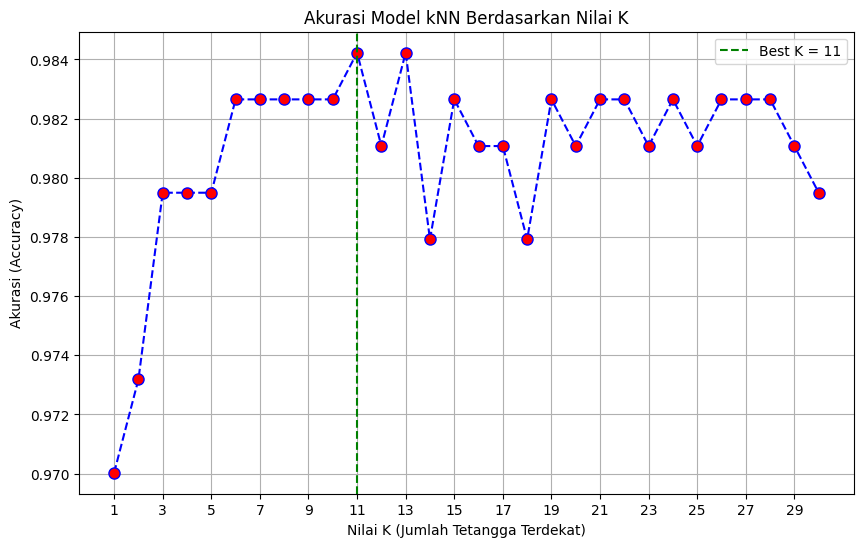

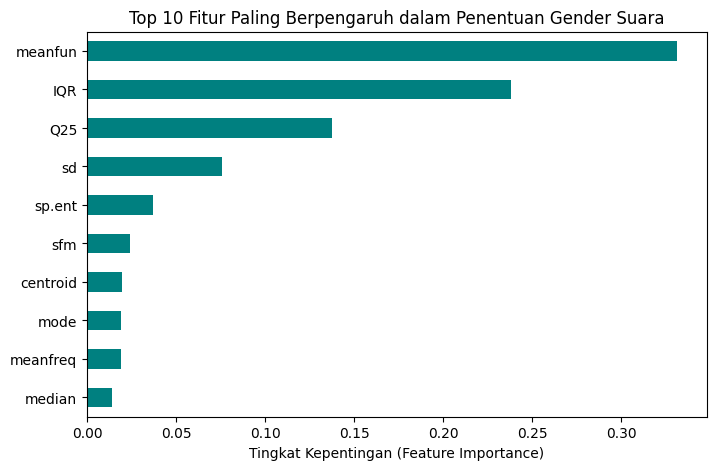

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.ensemble import RandomForestClassifier

# 1. LOAD DATASET
# Pastikan file voice.csv berada di direktori yang sama
df = pd.read_csv('voice.csv')

# Encode label 'male' dan 'female' menjadi numerik (0 dan 1)
le = LabelEncoder()
df['label'] = le.fit_transform(df['label'])

# Pisahkan fitur (X) dan target (y) awal
X_all = df.drop('label', axis=1)
y = df['label']

# ==============================================================================
# TUGAS 2: EKSPERIMEN SELEKSI FITUR (Mencari Fitur Paling Optimal)
# ==============================================================================
# Menggunakan Random Forest untuk menghitung tingkat kepentingan fitur (Feature Importance)
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_all, y)

# Mengurutkan fitur berdasarkan tingkat kepentingannya
feature_importances = pd.Series(rf_model.feature_importances_, index=X_all.columns)
best_features = feature_importances.nlargest(5).index.tolist() # Mengambil 5 fitur terbaik

print("--- TUGAS 2: FITUR TERBAIK ---")
print("Fitur paling optimal yang dipilih:", best_features)

# Membuat dataset baru hanya dengan fitur-fitur terbaik
X_optimized = df[best_features]

# ==============================================================================
# TUGAS 1: PEMBUATAN MODEL kNN (Dengan Fitur Optimal)
# ==============================================================================
# Pembagian data latih (80%) dan data uji (20%)
X_train, X_test, y_train, y_test = train_test_split(X_optimized, y, test_size=0.2, random_state=42)

# Feature Scaling (Sangat WAJIB untuk algoritma kNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ==============================================================================
# TUGAS 3: MENCARI NILAI K TERBAIK DAN VISUALISASI
# ==============================================================================
k_range = range(1, 31) # Uji nilai k dari 1 hingga 30
accuracies = []

for k in k_range:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train_scaled, y_train)
    y_pred = knn.predict(X_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred))

# Mencari K dengan akurasi tertinggi
best_k = k_range[np.argmax(accuracies)]
best_accuracy = max(accuracies)

print("\n--- TUGAS 3: NILAI K TERBAIK ---")
print(f"Nilai K terbaik adalah K = {best_k} dengan akurasi: {best_accuracy:.4f}")

# Evaluasi model final dengan K terbaik
final_knn = KNeighborsClassifier(n_neighbors=best_k)
final_knn.fit(X_train_scaled, y_train)
y_pred_final = final_knn.predict(X_test_scaled)
print("\nLaporan Klasifikasi Final:\n", classification_report(y_test, y_pred_final, target_names=le.classes_))

# Visualisasi Analisis K
plt.figure(figsize=(10, 6))
plt.plot(k_range, accuracies, marker='o', linestyle='dashed', color='blue', markerfacecolor='red', markersize=8)
plt.title('Akurasi Model kNN Berdasarkan Nilai K')
plt.xlabel('Nilai K (Jumlah Tetangga Terdekat)')
plt.ylabel('Akurasi (Accuracy)')
plt.xticks(np.arange(1, 31, step=2))
plt.grid(True)
plt.axvline(x=best_k, color='green', linestyle='--', label=f'Best K = {best_k}')
plt.legend()
plt.show()

# Visualisasi Feature Importance
plt.figure(figsize=(8, 5))
feature_importances.nlargest(10).plot(kind='barh', color='teal')
plt.title('Top 10 Fitur Paling Berpengaruh dalam Penentuan Gender Suara')
plt.xlabel('Tingkat Kepentingan (Feature Importance)')
plt.gca().invert_yaxis()
plt.show()

In [1]:
# Load library & dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

df = pd.read_csv('properti_multi_kota.csv')

# Imputasi missing value dengan median
for col in ['luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']:
    df[col] = df[col].fillna(df[col].median())

# Filter outlier ekstrem (hingga persentil ke-95) agar model stabil
df_clean = df[
    (df['luas_m2'] > 0) & (df['luas_m2'] <= df['luas_m2'].quantile(0.95)) &
    (df['luas_bangunan'] > 0) & (df['luas_bangunan'] <= df['luas_bangunan'].quantile(0.95)) &
    (df['jumlah_kamar'] > 0) & (df['jumlah_kamar'] <= 15) &
    (df['jumlah_kamar_mandi'] > 0) & (df['jumlah_kamar_mandi'] <= 15) &
    (df['harga'] > 1e7) & (df['harga'] <= df['harga'].quantile(0.95))
].copy()

# Membuat target biner (1 = Harga Tinggi/Mahal, 0 = Harga Rendah/Murah berdasarkan median)
median_harga = df_clean['harga'].median()
df_clean['target_harga'] = (df_clean['harga'] > median_harga).astype(int)

df_clean.head()

,sumber,lokasi,luas_m2,luas_bangunan,jumlah_kamar,jumlah_kamar_mandi,usia_bangunan,harga,target_harga
0,uas-properti/Jabodetabek,Tangerang,30.0,63.0,3.0,3.0,33.0,2.037543e+08,0
1,uas-properti/Jabodetabek,Bekasi,122.0,63.0,5.0,4.0,19.0,1.058032e+09,1
2,uas-properti/Jabodetabek,Bekasi,142.8,63.0,1.0,1.0,9.0,1.335793e+09,1
3,uas-properti/Jabodetabek,Bekasi,152.6,63.0,4.0,3.0,6.0,1.613771e+09,1
4,uas-properti/Jabodetabek,Depok,61.2,63.0,1.0,1.0,9.0,5.221562e+08,0


In [2]:
# Encoding kolom kategorikal lokasi
le = LabelEncoder()
df_clean['lokasi_encoded'] = le.fit_transform(df_clean['lokasi'].astype(str))

# Soal 2: Menentukan fitur-fitur yang paling optimal
# Fitur yang digunakan memberikan kontribusi informasi fisik dan wilayah properti
fitur_optimal = ['lokasi_encoded', 'luas_m2', 'luas_bangunan', 'jumlah_kamar', 'jumlah_kamar_mandi']
X = df_clean[fitur_optimal]
y = df_clean['target_harga']

# Split data (80% training, 20% testing) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Feature Scaling (Sangat penting untuk kNN agar jarak antar fitur seimbang)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Soal 1: Membuat dan melatih model kNN (menggunakan k=3 sebagai awal)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train_scaled, y_train)

# Evaluasi awal model
y_pred = knn.predict(X_test_scaled)
print(f"Akurasi Model kNN (k=3): {accuracy_score(y_test, y_pred):.4f}")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Akurasi Model kNN (k=3): 0.8587

Confusion Matrix:
 [[4839  824]
 [ 770 4851]]


Nilai k terbaik adalah 1 dengan akurasi: 0.8604


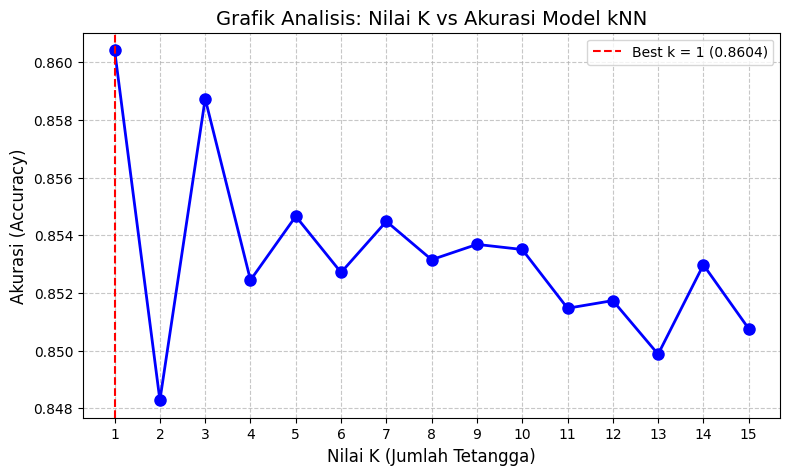

In [3]:
# Looping untuk mencari nilai k terbaik dari 1 sampai 15
akurasi_list = []
nilai_k = range(1, 16)

for k in nilai_k:
    model_knn = KNeighborsClassifier(n_neighbors=k)
    model_knn.fit(X_train_scaled, y_train)
    y_pred_k = model_knn.predict(X_test_scaled)
    akurasi_list.append(accuracy_score(y_test, y_pred_k))

# Menampilkan k terbaik
best_k = nilai_k[np.argmax(akurasi_list)]
best_acc = max(akurasi_list)
print(f"Nilai k terbaik adalah {best_k} dengan akurasi: {best_acc:.4f}")

# Visualisasi grafik analisis Nilai K vs Akurasi
plt.figure(figsize=(9, 5))
plt.plot(nilai_k, akurasi_list, marker='o', linestyle='-', color='b', linewidth=2, markersize=8)
plt.title('Grafik Analisis: Nilai K vs Akurasi Model kNN', fontsize=14)
plt.xlabel('Nilai K (Jumlah Tetangga)', fontsize=12)
plt.ylabel('Akurasi (Accuracy)', fontsize=12)
plt.xticks(nilai_k)
plt.grid(True, linestyle='--', alpha=0.7)
plt.axvline(x=best_k, color='r', linestyle='--', label=f'Best k = {best_k} ({best_acc:.4f})')
plt.legend()
plt.show()